# AC-OPF on the PJM 5-Bus Network: Dispatch, Losses, Voltages and LMPs

Full AC optimal power flow (AC-OPF) on the PJM 5-bus case, compared with economic dispatch (ED) and the lossless DC-OPF from the previous notebook. Active and reactive nodal prices (LMPs) and the line shadow price are taken from the Pyomo/IPOPT duals and cross-checked against PYPOWER. 

**Contents**
* Summary of Findings
* Network and Data
* Setup
* Admittance Calculation
* Baselines: ED and DC-OPF
* AC-OPF Model
* Results
* LMPs and Shadow Prices
* Comparison: ED vs DC-OPF vs AC-OPF
* Visual Summary
* Conclusion
* Limitations
* References

## Summary of Findings

* **AC-OPF costs *\$17,551.89/h*:** that is *\$72.00/h* (0.4%) more than the lossless DC-OPF (*\$17,479.90/h*) and *\$2,741.89/h* (18.5%) more than economic dispatch (*\$14,810/h*).
* **Most of the extra cost is congestion, not losses:** moving from ED to DC-OPF adds *\$2,669.90/h* (the network limit). Moving from DC-OPF to AC-OPF adds only *\$72.00/h*, because the generators must also cover *5.19 MW* of line losses (0.5% of the 1,000 MW demand).
* **The same line is binding:** Branch 6 (Bus 4 ↔ Bus 5) carries *240 MVA* at its sending end (Bus 5), exactly its thermal limit. All other branches stay below 67% loading.
* **Nodal prices spread, as in DC-OPF:** LMPs range from *\$10.00/MWh* at Bus 5 to *\$39.71/MWh* at Bus 4. They differ from the DC-OPF LMPs by at most *\$0.23/MWh*, because AC prices also include a marginal-loss component.
* **Transmission capacity still has marginal value:** Branch 6 has a shadow price of about *\$61.31/h* per additional MVA of rating (DC-OPF: *\$62.32/h* per MW).
* **Reactive power and voltage are now part of the answer:** Gens 1, 2 and 3 run at their reactive-power maximums, Bus 3 reaches the *1.10 p.u.* voltage limit, and reactive LMPs are positive at Buses 1 to 3 (*\$0.11* to *\$0.37*/MVAr·h) and zero at Buses 4 and 5.

The Pyomo/IPOPT results agree with an independent PYPOWER AC-OPF solution for the same test case.

## Network and Data
A standard power systems test case with 5 buses, 5 generators, and 6 transmission lines: https://github.com/power-grid-lib/pglib-opf/blob/master/pglib_opf_case5_pjm.m
<br>
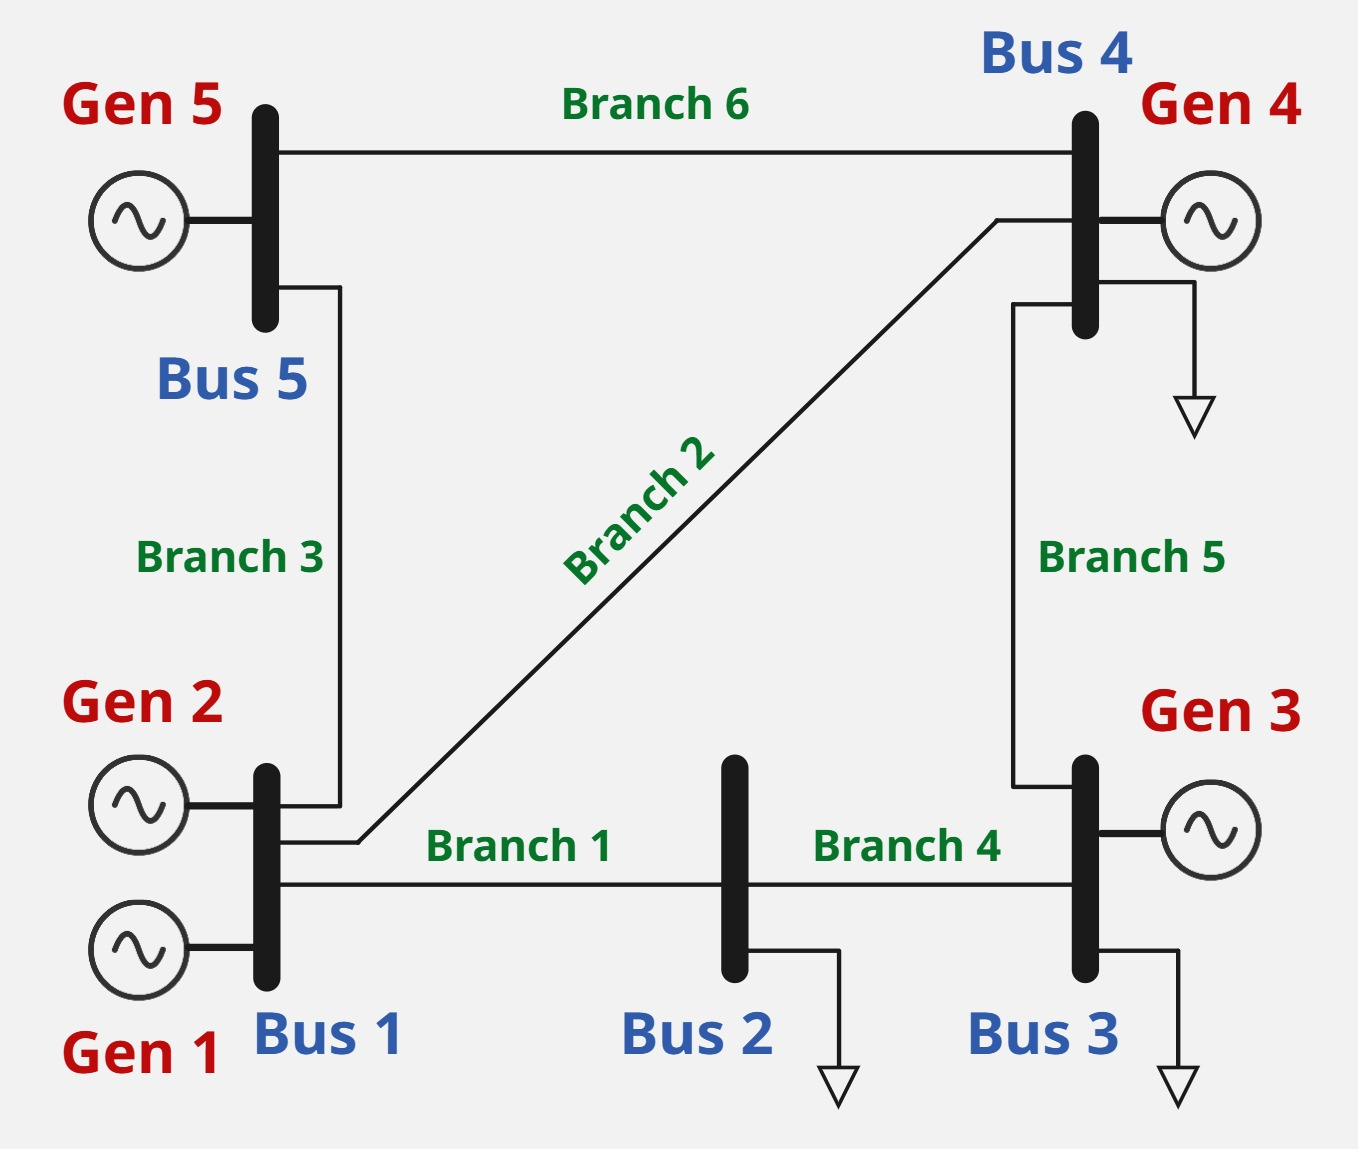


* **Bus data**:
  
| Bus | Type  | Pd (MW) | Qd (MVAr) | Generators connected            | V bounds (p.u.) |
|------|------|---------|-----------|----------------------------------|-----------------|
| 1    | PV    | 0       | 0         | Gen 1, Gen 2   | 0.9 - 1.1       |
| 2    | PQ    | 300     | 98.61     | -                                | 0.9 - 1.1       |
| 3    | PV    | 300     | 98.61     | Gen 3          | 0.9 - 1.1       |
| 4    | Slack | 400     | 131.47    | Gen 4          | 0.9 - 1.1       |
| 5    | PV    | 0       | 0         | Gen 5          | 0.9 - 1.1       |

Total demand: 1000 MW

> Bus 4 is the slack bus, but in this OPF that only means its angle is the reference ($\theta = 0$). Unlike in a plain power flow, the slack generator is not forced to absorb the mismatch: every generator is a free decision variable, so Gen 4 has no special role in dispatch.

* **Generator data**:
  
| Gen | Bus | Cost ($/MWh) | P bounds (MW) | Q bounds (MVAr) |
|-----|-----|---------------|----------------|-----------------|
| 1   | 1   | 14            | 0 - 40         | -30 - 30        |
| 2   | 1   | 15            | 0 - 170        | -127.5 - 127.5  |
| 3   | 3   | 30            | 0 - 520        | -390 - 390      |
| 4   | 4   | 40            | 0 - 200        | -150 - 150      |
| 5   | 5   | 10            | 0 - 600        | -450 - 450      |


* **Branch (line) data**:
  
| Branch | From bus → To bus | r (p.u.) | x (p.u.) | $b_c/2$ (p.u.) | Thermal limit (MVA) | Angle bounds (°) |
|--------|---------------------|-----------|-----------|-------------|----------------------|------------------|
| 1      | 1 → 2              | 0.00281   | 0.0281    | 0.00712     | 400                  | -30 to 30        |
| 2      | 1 → 4              | 0.00304   | 0.0304    | 0.00658     | 426                  | -30 to 30        |
| 3      | 1 → 5              | 0.00064   | 0.0064    | 0.03126     | 426                  | -30 to 30        |
| 4      | 2 → 3              | 0.00108   | 0.0108    | 0.01852     | 426                  | -30 to 30        |
| 5      | 3 → 4              | 0.00297   | 0.0297    | 0.00674     | 426                  | -30 to 30        |
| 6      | 4 → 5              | 0.00297   | 0.0297    | 0.00674     | 240                  | -30 to 30        |

Notes on the data:
* Costs are linear. Startup and no-load costs are excluded (commitment is not modelled), and all units are assumed on.
* Angle bounds apply to the angle difference across each branch, $\theta_i - \theta_j$.
* Thermal limits are **apparent power** limits (MVA) in AC-OPF, so reactive flow uses up line capacity too. The DC-OPF notebook had to treat the same numbers as MW limits.
* Reactive limits are $Q^{min} = -0.75\,P^{max}$ and $Q^{max} = +0.75\,P^{max}$ in the case file, and voltage magnitudes are bounded to 0.9 to 1.1 p.u. at every bus.
* $b_c/2$ is the line-charging susceptance at each end of the $\pi$-model, so a lightly loaded line also injects reactive power.
* Branch 6 at 240 MVA is the tightest line, and it sits between Bus 5 (cheapest and largest generator) and a load bus.

## Setup

The model uses Pyomo for algebraic modeling and IPOPT (Interior Point OPTimizer) for nonlinear programming (NLP). AC-OPF is non-linear and non-convex, so it needs an NLP solver.

Install once with `pip install pyomo idaes-pse numpy pandas matplotlib`, then run `idaes get-extensions` to download IPOPT.


In [1]:
# Dependencies
!pip install pyomo idaes-pse numpy pandas matplotlib
!idaes get-extensions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.9/5.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 41.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.9/351.9 kB 12.2 MB/s eta 0:00:00
  Attempting uninstall: pyomo
    Found existing installation: pyomo 6.10.0
    Uninstalling pyomo-6.10.0:
      Successfully uninstalled pyomo-6.10.0
Getting files...
Done
-----------------------------------------------------------------
IDAES Extensions Build Versions
Solvers:  v3.4.2 20240811 ubuntu2204-x86_64
Library:  v3.4.2 20240811 ubuntu2204-x86_64



In [2]:
import os
import idaes
import pyomo.environ as pyo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.4f}".format

# Make sure the IPOPT installed via IDAES extensions is discovered in PATH 
idaes_bin = idaes.bin_directory

if os.path.exists(idaes_bin):
    if idaes_bin not in os.environ.get("PATH", ""):
        os.environ["PATH"] = idaes_bin + os.pathsep + os.environ.get("PATH", "")
        print(f"Added IDAES bin ({idaes_bin}) to PATH.")
    else:
        print("IDAES bin already in PATH.")
else:
    print(f"Path does not exist: {idaes_bin}")

IDAES bin already in PATH.


In [3]:
# network data
baseMVA = 100.0
slackBus = 4

# gens = { gen_id: { bus_id, cost ($/MWh), Pmin, Pmax, Qmin, Qmax (p.u.) } }
gens = {
    1: {"bus": 1, "c": 14.0, "Pmin": 0.0, "Pmax": 0.40, "Qmin": -0.300, "Qmax": 0.300},
    2: {"bus": 1, "c": 15.0, "Pmin": 0.0, "Pmax": 1.70, "Qmin": -1.275, "Qmax": 1.275},
    3: {"bus": 3, "c": 30.0, "Pmin": 0.0, "Pmax": 5.20, "Qmin": -3.900, "Qmax": 3.900},
    4: {"bus": 4, "c": 40.0, "Pmin": 0.0, "Pmax": 2.00, "Qmin": -1.500, "Qmax": 1.500},
    5: {"bus": 5, "c": 10.0, "Pmin": 0.0, "Pmax": 6.00, "Qmin": -4.500, "Qmax": 4.500},
}

# buses = { bus_id: { Pd, Qd (p.u.), Vmin, Vmax (p.u.) } }
buses = {
    1: {"Pd": 0.00, "Qd": 0.0000, "Vmin": 0.9, "Vmax": 1.1},
    2: {"Pd": 3.00, "Qd": 0.9861, "Vmin": 0.9, "Vmax": 1.1},
    3: {"Pd": 3.00, "Qd": 0.9861, "Vmin": 0.9, "Vmax": 1.1},
    4: {"Pd": 4.00, "Qd": 1.3147, "Vmin": 0.9, "Vmax": 1.1},
    5: {"Pd": 0.00, "Qd": 0.0000, "Vmin": 0.9, "Vmax": 1.1},
}

# branches = { branch_id: { from, to, r, x, bc (total line charging), rate (p.u. MVA), angmax_deg } }
branches = {
    1: {"from": 1, "to": 2, "r": 0.00281, "x": 0.0281, "bc": 0.00712, "rate": 4.00, "angmax_deg": 30.0},
    2: {"from": 1, "to": 4, "r": 0.00304, "x": 0.0304, "bc": 0.00658, "rate": 4.26, "angmax_deg": 30.0},
    3: {"from": 1, "to": 5, "r": 0.00064, "x": 0.0064, "bc": 0.03126, "rate": 4.26, "angmax_deg": 30.0},
    4: {"from": 2, "to": 3, "r": 0.00108, "x": 0.0108, "bc": 0.01852, "rate": 4.26, "angmax_deg": 30.0},
    5: {"from": 3, "to": 4, "r": 0.00297, "x": 0.0297, "bc": 0.00674, "rate": 4.26, "angmax_deg": 30.0},
    6: {"from": 4, "to": 5, "r": 0.00297, "x": 0.0297, "bc": 0.00674, "rate": 2.40, "angmax_deg": 30.0},
}

In [4]:
gen_ids = sorted(gens)
bus_ids = sorted(buses)
branch_ids = sorted(branches)

## Admittance Calculation

Each branch's series conductance $g_{ij}$ and susceptance $b_{ij}$ are precomputed from $r_{ij}$ and $x_{ij}$.

For each branch $k = (i, j)$, the series admittance is:

$$ y_{ij} = g_{ij} + j b_{ij} = \frac{1}{ r_{ij} + j x_{ij} } = \frac{ r_{ij} - jx_{ij} }{ r_{ij}^2 + x_{ij}^2 } $$

so $g_{ij} = \dfrac{r_{ij}}{r_{ij}^2 + x_{ij}^2}$ and $b_{ij} = \dfrac{-x_{ij}}{r_{ij}^2 + x_{ij}^2}$. 

$b_{ij}$ is negative for an inductive line. The line-charging susceptance $b_{c,ij}$ is kept separate and enters the model as $b_{c,ij}/2$ at each end of the $\pi$-model.

In [5]:
# Pre-calculate branch series conductance (g) and susceptance (b)
adm = {}
for br, d in branches.items():
    den = d["r"]**2 + d["x"]**2
    adm[br] = {
        "g": d["r"] / den,
        "b": -d["x"] / den,
        "bc": d["bc"]
    }

In [6]:
# Helper mappings used in power balance and flow calculations

# 1. bus_to_generator[b] → list of generator IDs at bus b
bus_to_generator = {i: [] for i in bus_ids}
for g, d in gens.items():
    bus_to_generator[d["bus"]].append(g)

# 2. bus_to_branches[b] → list of branch IDs connected to bus b
bus_to_branches = {i: [] for i in bus_ids}
for br, d in branches.items():
    bus_to_branches[d["from"]].append(br)
    bus_to_branches[d["to"]].append(br)

# 3. other_end(br, i) → the bus at the other end of branch br from bus i
def other_end(br, i):
    f, t = branches[br]["from"], branches[br]["to"]
    return t if i == f else f

## Baselines: ED and DC-OPF

The comparison needs the two earlier models. Their results are taken from the previous notebook ([01_dcopf_pyomo.ipynb](https://github.com/vjkhtw/pjm5-dcopf/blob/main/notebooks/01_dcopf_pyomo.ipynb), solved with Pyomo/HiGHS and cross-checked with PYPOWER) and pasted below rather than re-solved here.

In [7]:
# Reference results from 01_dcopf_pyomo.ipynb 
ed_pg = np.array([40.0, 170.0, 190.0, 0.0, 600.0])                                # MW
ed_cost = 14810.0                                                                 # $/h
ed_lambda = 30.0                                                                  # $/MWh, system price

dc_pg = np.array([40.0, 170.0, 323.49484600, 0.0, 466.50515400])                  # MW
dc_cost = 17479.896925574154                                                      # $/h
dc_lmp = np.array([16.97735882, 26.38445952, 30.0, 39.94273632, 10.0])            # $/MWh
dc_mu6 = 62.32204211                                                              # $/h per MW, Branch 6
dc_flow = np.array([249.71676554, 186.78838859, -226.50515417,
                    -50.28323446, -26.78838944, -240.0])                          # MW, from → to

## AC-OPF Model

AC-OPF keeps the same objective as DC-OPF but replaces the linear network with the full AC power flow equations. The decision variables are $P_g$ and $Q_g$ for every generator, and the voltage magnitude $V_i$ and angle $\theta_i$ for every bus. 

$$\min \; \sum_g c_g P_g$$

subject to:
* **Active power balance at each bus *i*:** $\sum_{g \in i} P_g - P_{d,i} - \sum_{j} P_{ij} = 0$
* **Reactive power balance at each bus *i*:** $\sum_{g \in i} Q_g - Q_{d,i} - \sum_{j} Q_{ij} = 0$
* **Generator real power limits:** $P_g^{min} \le P_g \le P_g^{max}$
* **Generator reactive power limits:** $Q_g^{min} \le Q_g \le Q_g^{max}$
* **Voltage limits:** $V_i^{min} \le V_i \le V_i^{max}$
* **Line thermal limits (both ends):** $P_{ij}^2 + Q_{ij}^2 \le S_{ij,max}^2$ and $P_{ji}^2 + Q_{ji}^2 \le S_{ij,max}^2$
* **Branch angle difference limits:** $-\Delta\theta^{max}_{ij} \le \theta_i - \theta_j \le \Delta\theta^{max}_{ij}$
* **Slack bus reference:** $\theta_{slack} = 0$

Here $P_{ij}$ and $Q_{ij}$ are the flows leaving bus $i$ toward bus $j$ (defined in [Network Physics](#Network-Physics)). 

The problem is **non-convex**, so IPOPT finds a *local* optimum that can depend on the starting point (the same starting point is used for every run below). Reactive power has no direct cost: it has a price only through the constraints it relaxes.

### Initial guess

The initial solve uses a flat start: $V = 1.0$ p.u., $\theta = 0$, $P_g$ at the midpoint of its limits and $Q_g = 0$. Later sensitivity checks re-solve the model after changing the relevant line rating.

## Sets, parameters, variables and objective

In [8]:
model = pyo.ConcreteModel(name="AC_OPF_5_BUS")

# Sets
model.buses = pyo.Set(initialize = bus_ids)
model.gens = pyo.Set(initialize = gen_ids)
model.branches = pyo.Set(initialize = branch_ids)

# Parameters (rate is mutable so the Branch 6 shadow price can be checked later by re-solving)
model.Pd = pyo.Param(model.buses, initialize = {i: buses[i]["Pd"] for i in bus_ids})
model.Qd = pyo.Param(model.buses, initialize = {i: buses[i]["Qd"] for i in bus_ids})
model.c = pyo.Param(model.gens, initialize = {g: gens[g]["c"] for g in gen_ids})
model.rate = pyo.Param(model.branches, mutable=True, initialize = {br: branches[br]["rate"] for br in branch_ids})
model.angmax = pyo.Param(model.branches, initialize = {br: np.radians(branches[br]["angmax_deg"]) for br in branch_ids})

# Variables
model.Pg = pyo.Var(model.gens, bounds = lambda m, g: (gens[g]["Pmin"], gens[g]["Pmax"]), initialize = lambda m, g: (gens[g]['Pmin'] + gens[g]['Pmax']) / 2)
model.Qg = pyo.Var(model.gens, bounds = lambda m, g: (gens[g]["Qmin"], gens[g]["Qmax"]), initialize = 0)
model.V = pyo.Var(model.buses, bounds = lambda m, i: (buses[i]["Vmin"], buses[i]["Vmax"]), initialize = 1)
model.theta = pyo.Var(model.buses, bounds = (-np.pi, np.pi), initialize = 0)

# Objective: Minimize total hourly fuel cost ($/h)
model.obj = pyo.Objective(
    expr = baseMVA * sum(model.c[g] * model.Pg[g] for g in model.gens),
    sense = pyo.minimize
)

## Network Physics
With the $\pi$-model shunt charging $b_c/2$ at each terminal, the active and reactive power leaving bus $i$ toward bus $j$ are $P_{ij}$ and $Q_{ij}$. The same formulas with $i$ and $j$ swapped give the flows at the opposite terminal. The apparent power at **both terminals** must stay within the thermal limit, so AC-OPF imposes two constraints per line:

$$ P_{ij}^2+Q_{ij}^2\leq S_{\max,ij}^2 \qquad P_{ji}^2+Q_{ji}^2\leq S_{\max,ij}^2 $$

Unlike DC-OPF, the two end flows generally differ, and $P_{ij}+P_{ji}$ is the active power loss in the line.

In [9]:
# Flow functions

# 1. Active power flow leaving bus i toward bus j along branch br
def ac_P_flow(m, br, i, j):
    g, b = adm[br]["g"], adm[br]["b"]
    dtheta = m.theta[i] - m.theta[j]
    return g * m.V[i]**2 - m.V[i] * m.V[j] * (g * pyo.cos(dtheta) + b * pyo.sin(dtheta))

# 2. Reactive power flow leaving bus i toward bus j along branch br
def ac_Q_flow(m, br, i, j):
    g, b, bc = adm[br]["g"], adm[br]["b"], adm[br]["bc"]
    dtheta = m.theta[i] - m.theta[j]
    return -(b + bc / 2.0) * m.V[i]**2 - m.V[i] * m.V[j] * (g * pyo.sin(dtheta) - b * pyo.cos(dtheta))


## Constraints

In [10]:
# Constraint 1: Active power balance at each bus: generation - load - flow out = 0
def power_balance_P_rule(m, i):
    gen_P = sum(m.Pg[g] for g in bus_to_generator[i])
    flow_P = sum(ac_P_flow(m, br, i, other_end(br, i)) for br in bus_to_branches[i])
    return gen_P - m.Pd[i] - flow_P == 0

model.power_balance_P = pyo.Constraint(model.buses, rule = power_balance_P_rule)

# Constraint 2: Reactive power balance at each bus
def power_balance_Q_rule(m, i):
    gen_Q = sum(m.Qg[g] for g in bus_to_generator[i])
    flow_Q = sum(ac_Q_flow(m, br, i, other_end(br, i)) for br in bus_to_branches[i])
    return gen_Q - m.Qd[i] - flow_Q == 0 

model.power_balance_Q = pyo.Constraint(model.buses, rule = power_balance_Q_rule)

# Constraint 3: Apparent power (MVA) limit at both ends of every line
def line_limit_from_rule(m, br):
    f, t = branches[br]["from"], branches[br]["to"]
    return ac_P_flow(m, br, f, t)**2 + ac_Q_flow(m, br, f, t)**2 <= m.rate[br]**2

def line_limit_to_rule(m, br):
    f, t = branches[br]["from"], branches[br]["to"]
    return ac_P_flow(m, br, t, f)**2 + ac_Q_flow(m, br, t, f)**2 <= m.rate[br]**2

model.line_limit_from = pyo.Constraint(model.branches, rule = line_limit_from_rule)
model.line_limit_to = pyo.Constraint(model.branches, rule = line_limit_to_rule)

# Constraint 4: Branch angle difference limits
def angle_limits_rule(m, br):
    i = branches[br]["from"]
    j = branches[br]["to"]
    angmax = m.angmax[br]
    return (-angmax, m.theta[i] - m.theta[j], angmax)

model.angle_limits = pyo.Constraint(model.branches, rule = angle_limits_rule)

# Constraint 5: Voltage angle reference at the slack bus
model.slack_angle = pyo.Constraint(expr=model.theta[slackBus] == 0)

## Solve

In [11]:
# Request dual multipliers (LMPs and shadow prices)
model.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)

solver = pyo.SolverFactory("ipopt")
result = solver.solve(model)

print(f"Solver Status: {result.solver.status}")
print(f"Termination Condition: {result.solver.termination_condition}")

ac_cost = pyo.value(model.obj)
print(f"AC-OPF total cost: ${ac_cost:,.2f}/h")
print(f"DC-OPF total cost: ${dc_cost:,.2f}/h")
print(f"ED total cost:     ${ed_cost:,.2f}/h")

Solver Status: ok
Termination Condition: optimal
AC-OPF total cost: $17,551.89/h
DC-OPF total cost: $17,479.90/h
ED total cost:     $14,810.00/h


## Results
### 1. Generator Dispatch

In [12]:
dispatch = []
for g in gen_ids:
    dispatch.append({
        "Gen": g,
        "Bus": gens[g]["bus"],
        "Cost ($/MWh)": gens[g]["c"],
        "Pg (MW)": pyo.value(model.Pg[g]) * baseMVA,
        "Pmax (MW)": gens[g]["Pmax"] * baseMVA,
        "Qg (MVAr)": pyo.value(model.Qg[g]) * baseMVA,
        "Qmax (MVAr)": gens[g]["Qmax"] * baseMVA,
        "Operating cost ($/h)": pyo.value(model.Pg[g]) * gens[g]["c"] * baseMVA,
    })

total_ac_generation = sum(
    pyo.value(model.Pg[g]) * baseMVA for g in gen_ids
)

total_demand = sum(
    pyo.value(model.Pd[b]) * baseMVA for b in bus_ids
)

print(f"Total AC-OPF Generation: {total_ac_generation:.2f} MW")
print(f"Total Active Power Demand: {total_demand:.2f} MW")

dispatch_df = pd.DataFrame(dispatch)
dispatch_df

Total AC-OPF Generation: 1005.19 MW
Total Active Power Demand: 1000.00 MW


,Gen,Bus,Cost ($/MWh),Pg (MW),Pmax (MW),Qg (MVAr),Qmax (MVAr),Operating cost ($/h)
0,1,1,14.0000,40.0000,40.0000,30.0000,30.0000,560.0000
1,2,1,15.0000,170.0000,170.0000,127.5000,127.5000,"2,550.0000"
2,3,3,30.0000,324.4985,520.0000,390.0000,390.0000,"9,734.9548"
3,4,4,40.0000,0.0000,200.0000,-10.8023,150.0000,0.0000
4,5,5,10.0000,470.6936,600.0000,-165.0394,450.0000,"4,706.9360"


Total generation is 1,005.19 MW against 1,000 MW of demand: the extra 5.19 MW is the active power lost in the lines. Gens 1 and 2 run at their active maximums, Gen 5 (*\$10/MWh*) is held at 470.7 MW, below its 600 MW maximum, by the Branch 6 limit, Gen 3 (*\$30/MWh*) supplies most of the rest, and Gen 4 (*\$40/MWh*) is not needed.

On the reactive side, Gens 1, 2 and 3 are at their **Qmax** and Gens 4 and 5 absorb reactive power (negative Qg). Reactive power is limited here, which is why it has a price (see the reactive LMPs below).

### 2. Line Flows and Angle Differences

In [13]:
flows = []
for br in branch_ids:
    f, t = branches[br]["from"], branches[br]["to"]
    Pf = pyo.value(ac_P_flow(model, br, f, t)) * baseMVA
    Qf = pyo.value(ac_Q_flow(model, br, f, t)) * baseMVA
    Pt = pyo.value(ac_P_flow(model, br, t, f)) * baseMVA
    Qt = pyo.value(ac_Q_flow(model, br, t, f)) * baseMVA
    Sf, St = np.hypot(Pf, Qf), np.hypot(Pt, Qt)          # apparent power at each end (MVA)
    s_max = branches[br]["rate"] * baseMVA
    dtheta = np.degrees(pyo.value(model.theta[f] - model.theta[t]))
    flows.append({
        "Branch": br,
        "From": f,
        "To": t,
        "Pf (MW)": Pf,
        "Qf (MVAr)": Qf,
        "Sf (MVA)": Sf,
        "St (MVA)": St,
        "Limit (MVA)": s_max,
        "Loading (%)": max(Sf, St) / s_max * 100,
        "Loss (MW)": Pf + Pt,
        "Angle diff (deg)": dtheta,
        "Angle loading (%)": abs(dtheta) / branches[br]["angmax_deg"] * 100,
    })

flows_df = pd.DataFrame(flows)
total_loss_mw = flows_df["Loss (MW)"].sum()
print(f"Total transmission losses: {total_loss_mw:.2f} MW ({total_loss_mw / (total_demand) * 100:.2f}% of demand)")
flows_df

Total transmission losses: 5.19 MW (0.52% of demand)


,Branch,From,To,Pf (MW),Qf (MVAr),Sf (MVA),St (MVA),Limit (MVA),Loading (%),Loss (MW),Angle diff (deg),Angle loading (%)
0,1,1,2,252.3777,-42.4500,255.9228,257.2915,400.0000,64.3229,1.5840,3.5384,11.7948
1,2,1,4,187.8687,33.1319,190.7678,188.4951,426.0000,44.7812,0.9534,2.8038,9.3459
2,3,1,5,-230.2464,166.8181,284.3267,284.1712,426.0000,66.7433,0.4489,-0.7866,2.6219
3,4,2,3,-49.2063,-156.0684,163.6417,163.9258,426.0000,38.4802,0.2430,-0.1749,0.5831
4,5,3,4,-24.9508,135.1003,137.3850,133.6685,426.0000,32.2500,0.4660,-0.5597,1.8658
5,6,4,5,-238.5015,13.3104,238.8726,240.0000,240.0000,100.0000,1.4968,-3.5903,11.9678


A negative `Pf` means power moves against the listed from → to direction. Loading uses the larger of the two end flows, because losses make the sending end carry more than the receiving end.

* **Branch 6 is at 100% loading.** Its sending end (Bus 5) carries 240 MVA, so it is the only binding line. 
* **Reactive flow now uses line capacity.** Branch 3 moves ~230.2 MW but loads at 66.7%, because about 167 MVAr of reactive flow adds to its apparent power. DC-OPF reports only 53.2% for the same line, since it ignores reactive flow. Branch 4 (Bus 2 ↔ Bus 3) is the most extreme case: ~49 MW of active flow, but ~164 MVA of apparent power.
* **Losses are 5.19 MW in total**, with Branches 1 and 6 losing the most (about 1.6 MW and 1.5 MW).
* The largest angle difference is $3.59^{\circ}$ (12% of the $30^{\circ}$ bound), so the angle limits are not close to binding.


### 3. Bus Voltages and Angles

In [14]:
bus_rows = []
for i in bus_ids:
    v = pyo.value(model.V[i])
    at_bound = "Vmax" if abs(v - buses[i]["Vmax"]) < 1e-4 else ("Vmin" if abs(v - buses[i]["Vmin"]) < 1e-4 else "-")
    bus_rows.append({
        "Bus": i,
        "V (p.u.)": v,
        "At bound": at_bound,
        "Angle (deg)": np.degrees(pyo.value(model.theta[i])),
        "Gen P (MW)": sum(pyo.value(model.Pg[g]) for g in bus_to_generator[i]) * baseMVA,
        "Load P (MW)": buses[i]["Pd"] * baseMVA,
        "Gen Q (MVAr)": sum(pyo.value(model.Qg[g]) for g in bus_to_generator[i]) * baseMVA,
        "Load Q (MVAr)": buses[i]["Qd"] * baseMVA,
    })
display(pd.DataFrame(bus_rows))

# balance check: generation - load - flow out should be zero at every bus
mismatch_P = max(abs(pyo.value(sum(model.Pg[g] for g in bus_to_generator[i]) - model.Pd[i]
                  - sum(ac_P_flow(model, br, i, other_end(br, i)) for br in bus_to_branches[i]))) for i in bus_ids) * baseMVA
mismatch_Q = max(abs(pyo.value(sum(model.Qg[g] for g in bus_to_generator[i]) - model.Qd[i]
                  - sum(ac_Q_flow(model, br, i, other_end(br, i)) for br in bus_to_branches[i]))) for i in bus_ids) * baseMVA
print(f"Largest bus balance mismatch: {mismatch_P:.1e} MW (active), {mismatch_Q:.1e} MVAr (reactive)")

,Bus,V (p.u.),At bound,Angle (deg),Gen P (MW),Load P (MW),Gen Q (MVAr),Load Q (MVAr)
0,1,1.0776,-,2.8038,210.0000,0.0000,157.5000,0.0000
1,2,1.0841,-,-0.7346,0.0000,300.0000,0.0000,98.6100
2,3,1.1000,Vmax,-0.5597,324.4985,300.0000,390.0000,98.6100
3,4,1.0641,-,0.0000,0.0000,400.0000,-10.8023,131.4700
4,5,1.0691,-,3.5903,470.6936,0.0000,-165.0394,0.0000


Largest bus balance mismatch: 1.5e-05 MW (active), 1.4e-04 MVAr (reactive)


* **Voltages** range from 1.064 to 1.100 p.u. Bus 3 sits exactly at its upper limit, and Gen 3 there is at its reactive limit, so no more reactive support is available at that bus. Voltages are high overall partly because lightly loaded lines inject reactive power through their line charging.
* **Angles** are small. Bus 4 is the reference (0 deg). Buses 1 and 5, which export the most (210 MW and 471 MW), sit at the highest angles, and the largest difference across any line is 3.59 deg (Branch 6).
* **Balance** closes at every bus: the active and reactive mismatches are at solver precision.

## LMPs and Shadow Prices

IPOPT returns a multiplier (dual) for every constraint. Three are reported here:

* **Active LMP, $\lambda_P$ (\$/MWh):** the dual of the active power balance at a bus.
* **Reactive LMP, $\lambda_Q$ (\$/MVAr·h):** the dual of the reactive power balance. This price only exists in AC-OPF.
* **Line shadow price, $\mu$ (\$/h per MVA):** the dual of a line's thermal limit. It is zero for any line that is not at its limit.

The multipliers on voltage, generator and angle bounds also exist but add little here, so they are not reported.

> **Unit conversion.** The model is in p.u. with a cost objective in \$/h, so the balance duals come out per p.u. and are divided by `baseMVA`. The thermal limit is written as $P^2 + Q^2 \le S_{max}^2$, so its raw dual is per p.u.$^2$. Per MVA of rating it is $|\text{dual}| \cdot 2 S_{max}^{pu} / \text{baseMVA}$ (derivation in the note, §4.3). Line duals are taken as absolute values, and values around $10^{-9}$ are solver noise and are set to zero.

### 1. Nodal Prices

In [15]:
lmp_P = {i: model.dual[model.power_balance_P[i]] / baseMVA for i in bus_ids}
lmp_Q = {i: model.dual[model.power_balance_Q[i]] / baseMVA for i in bus_ids}
lmp_Q = {i: (v if abs(v) > 1e-6 else 0.0) for i, v in lmp_Q.items()}  

pd.DataFrame({
    "Bus": bus_ids,
    "Active LMP ($/MWh)": [lmp_P[i] for i in bus_ids],
    "Reactive LMP ($/MVAr·h)": [lmp_Q[i] for i in bus_ids],
})

,Bus,Active LMP ($/MWh),Reactive LMP ($/MVAr·h)
0,1,16.9351,0.3570
1,2,26.5499,0.3674
2,3,30.0000,0.1051
3,4,39.7121,0.0000
4,5,10.0000,0.0000


* **Active LMPs** range from *\$10.00* at Bus 5 (behind the bottleneck, where cheap Gen 5 power is plentiful) to *\$39.71* at Bus 4 (an importer that cheap power cannot reach). Buses 3 and 5 sit at the marginal cost of the generator located there (*\$30* and *\$10*), and Bus 4 stays just below Gen 4's *\$40* offer, so Gen 4 remains off.
* **Reactive LMPs** are positive at Buses 1, 2 and 3 (*\$0.357*, *\$0.367*, *\$0.105* per MVAr·h) and zero at Buses 4 and 5. Gens 1, 2 and 3 are at their reactive maximums, so extra reactive demand near them has to be served from farther away, over lines that waste power on the way. Gens 4 and 5 still have reactive headroom, so reactive power costs nothing at their buses. In this case, reactive LMPs are small, at about 0.4% to 2% of the active LMPs. However, reactive LMPs can be much larger when generator reactive-power limits or voltage constraints bind.

### 2. Line Shadow Prices

In [16]:
def line_shadow_price(br):
    raw = abs(model.dual.get(model.line_limit_from[br], 0.0)) + abs(model.dual.get(model.line_limit_to[br], 0.0))
    value = raw * 2 * branches[br]["rate"] / baseMVA   
    return value if value > 1e-6 else 0.0

mu = {br: line_shadow_price(br) for br in branch_ids}
pd.DataFrame({
    "Branch": branch_ids,
    "From": [branches[br]["from"] for br in branch_ids],
    "To": [branches[br]["to"] for br in branch_ids],
    "Loading (%)": flows_df["Loading (%)"],
    "Shadow price ($/h per MVA)": [mu[br] for br in branch_ids],
})

,Branch,From,To,Loading (%),Shadow price ($/h per MVA)
0,1,1,2,64.3229,0.0000
1,2,1,4,44.7812,0.0000
2,3,1,5,66.7433,0.0000
3,4,2,3,38.4802,0.0000
4,5,3,4,32.2500,0.0000
5,6,4,5,100.0000,61.3109


Only **Branch 6** has a nonzero shadow price, about *\$61.31* per hour per additional MVA of thermal rating. Near the current optimum, raising this rating by 1 MVA is expected to cut operating cost by about that much, as long as the set of binding constraints does not change. It is a marginal sensitivity, not a constant saving for any increase in capacity.

**Direct Check:** When raising the Branch 6 rating by 1 MVA, re-solving and comparing the cost change with the dual-based value, the difference should be close but not identical, as the dual is a slope and 1 MVA is a finite step.

In [17]:
base_cost = pyo.value(model.obj)

model.rate[6] = branches[6]["rate"] + 1.0 / baseMVA          # +1 MVA on Branch 6
solver.solve(model)
cost_relaxed = pyo.value(model.obj)

model.rate[6] = branches[6]["rate"]                          # restore the original rating and re-solve
solver.solve(model)

print(f"Cost change for +1 MVA on Branch 6: ${base_cost - cost_relaxed:,.2f}/h")
print(f"Dual-based shadow price:            ${mu[6]:,.2f}/h per MVA")

Cost change for +1 MVA on Branch 6: $61.30/h
Dual-based shadow price:            $61.31/h per MVA


### 3. Cross-check against PYPOWER
The reference values come from `04_acopf_pypower_reference.ipynb`, which solves the same case with the same 0.9 to 1.1 p.u. voltage limits.

In [18]:
# PYPOWER reference results from 04_acopf_pypower_reference.ipynb
pp_cost = 17551.891527133434
pp_pg = np.array([39.9999742, 169.999961, 324.498148, 0.000263520422, 470.693749])         # MW
pp_vm = np.array([1.07761726, 1.08406428, 1.09999952, 1.06413689, 1.0690703])              # p.u.
pp_lmp_p = np.array([16.93508208, 26.54990768, 30.00000015, 39.71208642, 10.00000043])     # $/MWh
pp_lmp_q = np.array([0.357041258, 0.367385756, 0.105113532, 0.0, 0.0])                     # $/MVAr.h
pp_mu = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 61.31083517])                                   # $/h per MVA

pyomo_vals = {
    "Total cost ($/h)": (np.array([pyo.value(model.obj)]), np.array([pp_cost])),
    "Generator output (MW)": (np.array([pyo.value(model.Pg[g]) * baseMVA for g in gen_ids]), pp_pg),
    "Voltage magnitude (p.u.)": (np.array([pyo.value(model.V[i]) for i in bus_ids]), pp_vm),
    "Active LMP ($/MWh)": (np.array([lmp_P[i] for i in bus_ids]), pp_lmp_p),
    "Reactive LMP ($/MVAr·h)": (np.array([lmp_Q[i] for i in bus_ids]), pp_lmp_q),
    "Line shadow price ($/h per MVA)": (np.array([mu[br] for br in branch_ids]), pp_mu),
}
crosscheck = pd.DataFrame({
    "Quantity": list(pyomo_vals),
    "Max abs difference": [f"{np.max(np.abs(a - b)):.1e}" for a, b in pyomo_vals.values()],
})
crosscheck

,Quantity,Max abs difference
0,Total cost ($/h),7.0e-04
1,Generator output (MW),3.5e-04
2,Voltage magnitude (p.u.),4.8e-07
3,Active LMP ($/MWh),1.8e-06
4,Reactive LMP ($/MVAr·h),1.2e-06
5,Line shadow price ($/h per MVA),7.4e-05


Pyomo/IPOPT and PYPOWER agree on cost, dispatch, voltages, both sets of LMPs and the line shadow price. The largest differences are of the order of the solvers' tolerances, so both implementations describe the same AC-OPF and reach the same local optimum.
> Agreement between two solvers (Pyomo/IPOPT vs PYPOWER) shows that both formulations match and reach the same local solution. It does not prove global optimality.

## Comparison: ED vs DC-OPF vs AC-OPF
Each model adds more physics to the one before it, and each addition has a price. ED has no network, DC-OPF adds line limits, and AC-OPF adds losses, reactive power and voltage limits.

In [19]:
ac_pg = np.array([pyo.value(model.Pg[g]) * baseMVA for g in gen_ids])
ac_lmp = np.array([lmp_P[i] for i in bus_ids])

summary_df = pd.DataFrame({
    "Model": ["ED", "DC-OPF", "AC-OPF"],
    "Network": ["none (single node)", "lossless, MW limits", "full AC, MVA limits"],
    "Cost ($/h)": [ed_cost, dc_cost, ac_cost],
    "Generation (MW)": [ed_pg.sum(), dc_pg.sum(), ac_pg.sum()],
})
summary_df["Losses (MW)"] = summary_df["Generation (MW)"] - total_demand
summary_df["Cost vs ED ($/h)"] = summary_df["Cost ($/h)"] - ed_cost
summary_df["Cost vs ED (%)"] = summary_df["Cost vs ED ($/h)"] / ed_cost * 100
summary_df["LMP range ($/MWh)"] = [f"{ed_lambda:.2f} (single price)",
                                   f"{dc_lmp.min():.2f} to {dc_lmp.max():.2f}",
                                   f"{ac_lmp.min():.2f} to {ac_lmp.max():.2f}"]
summary_df["Binding line"] = ["not modelled", "Branch 6", "Branch 6"]
summary_df

,Model,Network,Cost ($/h),Generation (MW),Losses (MW),Cost vs ED ($/h),Cost vs ED (%),LMP range ($/MWh),Binding line
0,ED,none (single node),"14,810.0000","1,000.0000",0.0000,0.0000,0.0000,30.00 (single price),not modelled
1,DC-OPF,"lossless, MW limits","17,479.8969","1,000.0000",0.0000,"2,669.8969",18.0277,10.00 to 39.94,Branch 6
2,AC-OPF,"full AC, MVA limits","17,551.8908","1,005.1921",5.1921,"2,741.8908",18.5138,10.00 to 39.71,Branch 6


### Dispatch

In [20]:
dispatch_cmp = pd.DataFrame({
    "Gen": gen_ids,
    "Bus": [gens[g]["bus"] for g in gen_ids],
    "Cost ($/MWh)": [gens[g]["c"] for g in gen_ids],
    "ED Pg (MW)": ed_pg,
    "DC-OPF Pg (MW)": dc_pg,
    "AC-OPF Pg (MW)": ac_pg,
    "AC - DC (MW)": ac_pg - dc_pg,
})
dispatch_cmp

,Gen,Bus,Cost ($/MWh),ED Pg (MW),DC-OPF Pg (MW),AC-OPF Pg (MW),AC - DC (MW)
0,1,1,14.0000,40.0000,40.0000,40.0000,0.0000
1,2,1,15.0000,170.0000,170.0000,170.0000,0.0000
2,3,3,30.0000,190.0000,323.4948,324.4985,1.0036
3,4,4,40.0000,0.0000,0.0000,0.0000,0.0000
4,5,5,10.0000,600.0000,466.5052,470.6936,4.1884


* **ED to DC-OPF:** the Branch 6 limit forces Gen 5 down by about 133.5 MW, and Gen 3 replaces the gap.
* **DC-OPF to AC-OPF:** the dispatch moves only slightly. Gen 5 produces 4.19 MW more and Gen 3 produces 1.00 MW more, which together cover the 5.19 MW of line losses.

### Line loading

In [21]:
rates_mva = np.array([branches[br]["rate"] * baseMVA for br in branch_ids])
flows_df["DC-OPF loading (%)"] = np.abs(dc_flow) / rates_mva * 100

loading_cmp = pd.DataFrame({
    "Branch": branch_ids,
    "DC-OPF loading (%)": flows_df["DC-OPF loading (%)"],
    "AC-OPF loading (%)": flows_df["Loading (%)"],
})
loading_cmp["AC - DC (points)"] = loading_cmp["AC-OPF loading (%)"] - loading_cmp["DC-OPF loading (%)"]
loading_cmp

,Branch,DC-OPF loading (%),AC-OPF loading (%),AC - DC (points)
0,1,62.4292,64.3229,1.8937
1,2,43.8470,44.7812,0.9341
2,3,53.1702,66.7433,13.5731
3,4,11.8036,38.4802,26.6766
4,5,6.2884,32.2500,25.9616
5,6,100.0000,100.0000,0.0000


* **Branch 6 is at 100% in both models**, so the same line is the bottleneck.
* **AC loading is higher where reactive flow is large.** Branch 3 loads at 66.7% in AC against 53.2% in DC, and Branch 4 at 38.5% against 11.8%. DC-OPF considers active power alone, whereas AC-OPF accounts for apparent power, including reactive flow. Consequently, DC-OPF can understate line loading and overstate the remaining thermal margin. This difference is particularly visible on Branches 3 and 4.

### Prices

In [22]:
lmp_cmp = pd.DataFrame({
    "Bus": bus_ids,
    "ED ($/MWh)": ed_lambda,
    "DC-OPF ($/MWh)": dc_lmp,
    "AC-OPF ($/MWh)": ac_lmp,
    "AC - DC ($/MWh)": ac_lmp - dc_lmp,
})
display(lmp_cmp)

print(f"Cost of congestion (DC-OPF - ED):     ${dc_cost - ed_cost:>9,.2f}/h  ({(dc_cost - ed_cost) / ed_cost * 100:.1f}%)")
print(f"Added cost of AC physics (AC - DC):   ${ac_cost - dc_cost:>9,.2f}/h  ({(ac_cost - dc_cost) / dc_cost * 100:.2f}%)")
print(f"Total cost over ED (AC - ED):         ${ac_cost - ed_cost:>9,.2f}/h  ({(ac_cost - ed_cost) / ed_cost * 100:.1f}%)")
print(f"Branch 6 shadow price: DC-OPF ${dc_mu6:.2f}/h per MW | AC-OPF ${mu[6]:.2f}/h per MVA")

,Bus,ED ($/MWh),DC-OPF ($/MWh),AC-OPF ($/MWh),AC - DC ($/MWh)
0,1,30.0000,16.9774,16.9351,-0.0423
1,2,30.0000,26.3845,26.5499,0.1654
2,3,30.0000,30.0000,30.0000,0.0000
3,4,30.0000,39.9427,39.7121,-0.2306
4,5,30.0000,10.0000,10.0000,0.0000


Cost of congestion (DC-OPF - ED):     $ 2,669.90/h  (18.0%)
Added cost of AC physics (AC - DC):   $    71.99/h  (0.41%)
Total cost over ED (AC - ED):         $ 2,741.89/h  (18.5%)
Branch 6 shadow price: DC-OPF $62.32/h per MW | AC-OPF $61.31/h per MVA


* **ED → DC-OPF: the network matters most.** The Branch 6 limit costs *\$2,669.90/h* (18.0%) and splits the single ED price into a nodal spread.
* **DC-OPF → AC-OPF: AC physics is a second-order correction here.** It adds *\$72.00/h* (0.4%), almost all of it from generating the extra 5.19 MW of losses (at roughly the Bus 4 to Bus 5 price range, \$10 to \$40/MWh).
* **The congestion picture is unchanged.** The same line binds, Gen 5 and Gen 3 are still the only units that move, and Gen 4 stays off. DC-OPF gave the right answer to "where is the bottleneck and what does it cost", which is why it is widely used for market pricing.
* **What only AC-OPF can show** is reactive power and voltage: Qg limits at Gens 1 to 3, Bus 3 at 1.10 p.u., reactive LMPs, and the extra line loading caused by reactive flow (Branches 3 and 4).

## Visual Summary

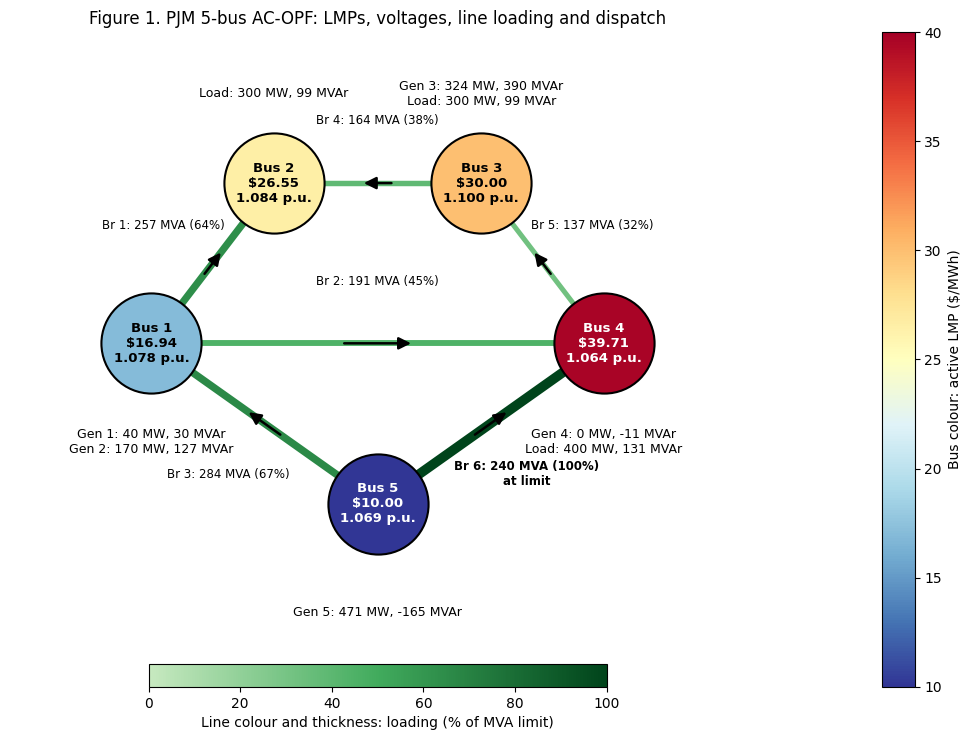

In [23]:
from matplotlib.colors import LinearSegmentedColormap

flow_mw = dict(zip(flows_df["Branch"], flows_df["Pf (MW)"]))
loading = dict(zip(flows_df["Branch"], flows_df["Loading (%)"]))
s_mva = {br: max(flows_df.loc[flows_df["Branch"] == br, "Sf (MVA)"].iloc[0],
                 flows_df.loc[flows_df["Branch"] == br, "St (MVA)"].iloc[0]) for br in branch_ids}
pg_mw = {g: pyo.value(model.Pg[g]) * baseMVA for g in gen_ids}
qg_mvar = {g: pyo.value(model.Qg[g]) * baseMVA for g in gen_ids}
vm = {i: pyo.value(model.V[i]) for i in bus_ids}

pos = {1: (0.0, 0.0), 2: (1.3, 1.7), 3: (3.5, 1.7), 4: (4.8, 0.0), 5: (2.4, -1.7)}
notes = {1: (0.0, -1.05), 2: (1.3, 2.65), 3: (3.5, 2.65), 4: (4.8, -1.05), 5: (2.4, -2.85)}

bus_cmap = plt.cm.RdYlBu_r                                   # bus colour = LMP
bus_norm = plt.Normalize(vmin=10, vmax=40)
line_cmap = LinearSegmentedColormap.from_list("load", ["#c7e9c0", "#41ab5d", "#00441b"])   # line colour = loading
line_norm = plt.Normalize(vmin=0, vmax=100)

fig, ax = plt.subplots(figsize=(11, 7.5))

for br in branch_ids:
    i, j = branches[br]["from"], branches[br]["to"]
    (x1, y1), (x2, y2) = pos[i], pos[j]
    congested = loading[br] >= 99.9
    col = line_cmap(line_norm(loading[br]))
    ax.plot([x1, x2], [y1, y2], color=col, lw=2 + loading[br] / 100 * 5, zorder=1, solid_capstyle="round")
    # arrow on the line, in the direction of the active power flow
    s, e = ((x1, y1), (x2, y2)) if flow_mw[br] >= 0 else ((x2, y2), (x1, y1))
    a = (s[0] + 0.42 * (e[0] - s[0]), s[1] + 0.42 * (e[1] - s[1]))
    b = (s[0] + 0.58 * (e[0] - s[0]), s[1] + 0.58 * (e[1] - s[1]))
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8, mutation_scale=18), zorder=3)
    # label beside the line, pushed away from the centre of the network
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    nx_, ny_ = -(y2 - y1), (x2 - x1)
    norm_ = np.hypot(nx_, ny_); nx_, ny_ = nx_ / norm_, ny_ / norm_
    if nx_ * (mx - 2.4) + ny_ * (my - 0.0) < 0 or (abs(mx - 2.4) < 1e-9 and abs(my) < 1e-9 and ny_ < 0):
        nx_, ny_ = -nx_, -ny_
    label = f"Br {br}: {s_mva[br]:.0f} MVA ({loading[br]:.0f}%)" + ("\nat limit" if congested else "")
    ax.text(mx + 0.66 * nx_, my + 0.66 * ny_, label, ha="center", va="center", fontsize=8.5,
            fontweight="bold" if congested else "normal", zorder=4,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))

for i in bus_ids:
    x, y = pos[i]
    ax.scatter([x], [y], s=5200, color=bus_cmap(bus_norm(lmp_P[i])), edgecolor="black", linewidth=1.5, zorder=5)
    txt_col = "white" if (lmp_P[i] < 15 or lmp_P[i] > 35) else "black"
    ax.text(x, y, f"Bus {i}\n${lmp_P[i]:.2f}\n{vm[i]:.3f} p.u.", ha="center", va="center", fontsize=9.5, fontweight="bold", color=txt_col, zorder=6)
    lines = [f"Gen {g}: {pg_mw[g]:.0f} MW, {qg_mvar[g]:.0f} MVAr" for g in bus_to_generator[i]]
    if buses[i]["Pd"] > 0:
        lines.append(f"Load: {buses[i]['Pd'] * baseMVA:.0f} MW, {buses[i]['Qd'] * baseMVA:.0f} MVAr")
    nx_, ny_ = notes[i]
    ax.text(nx_, ny_, "\n".join(lines), ha="center", va="center", fontsize=9, color="black")

cb1 = fig.colorbar(plt.cm.ScalarMappable(norm=bus_norm, cmap=bus_cmap), ax=ax, fraction=0.035, pad=0.02)
cb1.set_label("Bus colour: active LMP ($/MWh)")
cb2 = fig.colorbar(plt.cm.ScalarMappable(norm=line_norm, cmap=line_cmap), ax=ax, orientation="horizontal",
                   fraction=0.035, pad=0.0, shrink=0.5)
cb2.set_label("Line colour and thickness: loading (% of MVA limit)")

ax.set_xlim(-1.5, 6.3); ax.set_ylim(-3.4, 3.3)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Figure 1. PJM 5-bus AC-OPF: LMPs, voltages, line loading and dispatch", fontsize=12)
plt.tight_layout()
plt.show()

**Figure 1** shows the network. Bus colour and the first number inside each bus are its active LMP, and the second is its voltage magnitude. Line colour and thickness show loading as a share of the MVA limit (darkest and thickest = at its limit), arrows show the direction of active power flow, and the label gives apparent power. The text beside each bus gives its generation (MW and MVAr) and load. Only Branch 6 is at its limit.

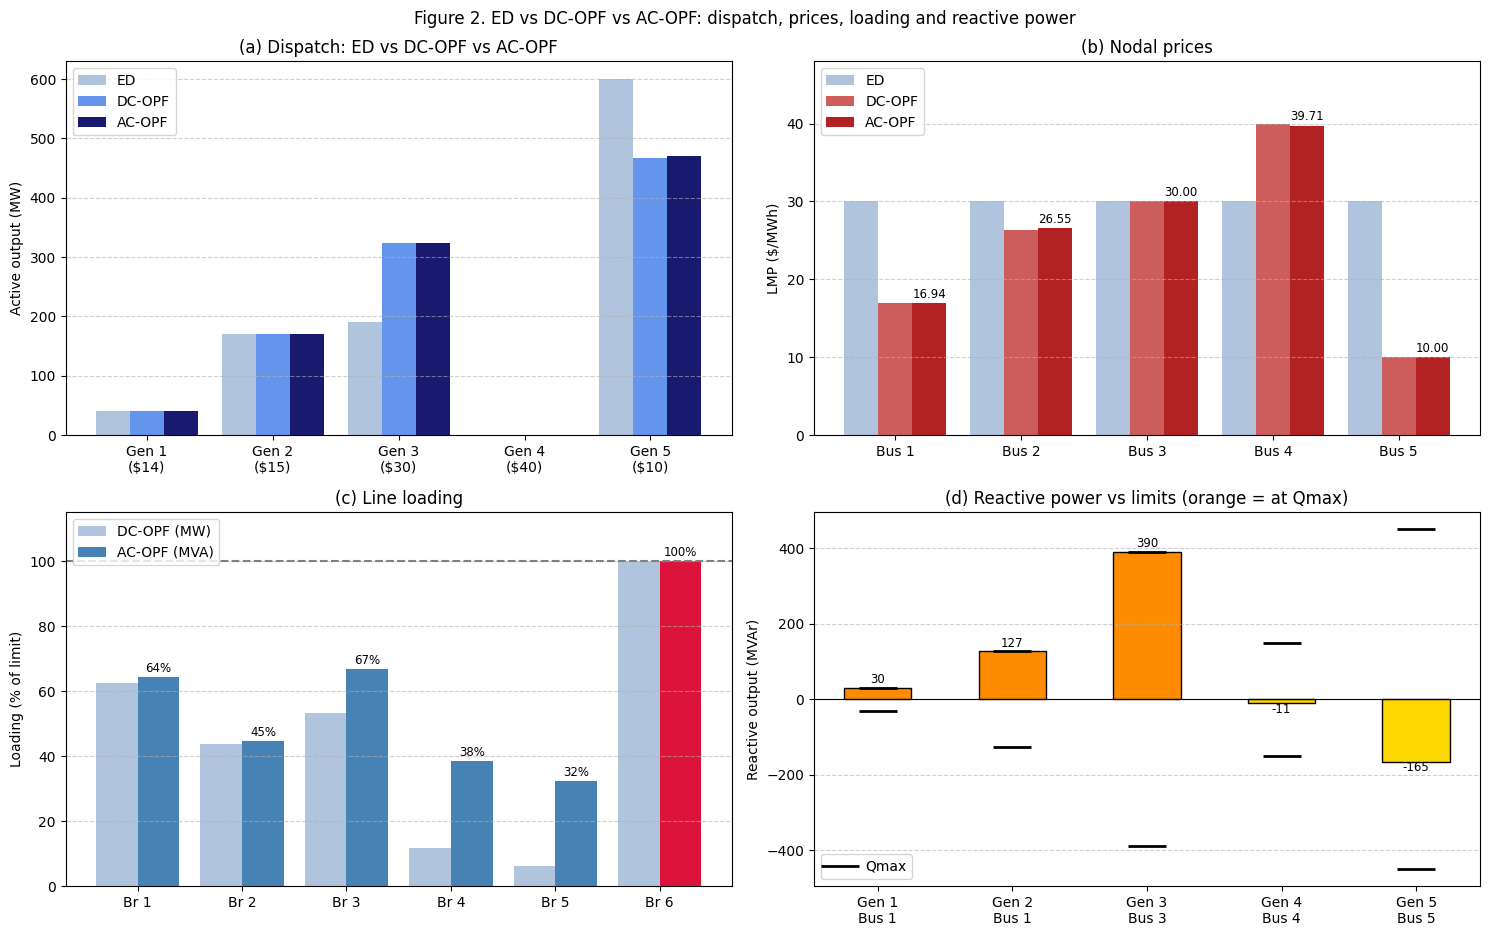

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# (a) dispatch: ED vs DC-OPF vs AC-OPF
w = 0.27
xg = np.arange(len(gen_ids))
axes[0, 0].bar(xg - w, ed_pg, w, label="ED", color="lightsteelblue")
axes[0, 0].bar(xg, dc_pg, w, label="DC-OPF", color="cornflowerblue")
axes[0, 0].bar(xg + w, ac_pg, w, label="AC-OPF", color="midnightblue")
axes[0, 0].set_xticks(xg)
axes[0, 0].set_xticklabels([f"Gen {g}\n(${gens[g]['c']:.0f})" for g in gen_ids])
axes[0, 0].set(ylabel="Active output (MW)", title="(a) Dispatch: ED vs DC-OPF vs AC-OPF")
axes[0, 0].legend()
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.6)

# (b) LMP per bus
xb = np.arange(len(bus_ids))
axes[0, 1].bar(xb - w, [ed_lambda] * len(bus_ids), w, label="ED", color="lightsteelblue")
axes[0, 1].bar(xb, dc_lmp, w, label="DC-OPF", color="indianred")
axes[0, 1].bar(xb + w, ac_lmp, w, label="AC-OPF", color="firebrick")
for k, v in enumerate(ac_lmp):
    axes[0, 1].text(k + w, v + 0.7, f"{v:.2f}", ha="center", fontsize=8.5)
axes[0, 1].set_xticks(xb)
axes[0, 1].set_xticklabels([f"Bus {i}" for i in bus_ids])
axes[0, 1].set(ylabel="LMP ($/MWh)", title="(b) Nodal prices", ylim=(0, 48))
axes[0, 1].legend(loc="upper left")
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.6)

# (c) line loading: DC-OPF (MW limit) vs AC-OPF (MVA limit)
xl = np.arange(len(branch_ids))
axes[1, 0].bar(xl - 0.2, flows_df["DC-OPF loading (%)"], 0.4, label="DC-OPF (MW)", color="lightsteelblue")
axes[1, 0].bar(xl + 0.2, flows_df["Loading (%)"], 0.4, label="AC-OPF (MVA)",
               color=["crimson" if l >= 99.9 else "steelblue" for l in flows_df["Loading (%)"]])
axes[1, 0].axhline(100, ls="--", color="gray")
for k, v in enumerate(flows_df["Loading (%)"]):
    axes[1, 0].text(k + 0.2, v + 1.5, f"{v:.0f}%", ha="center", fontsize=8.5)
axes[1, 0].set_xticks(xl)
axes[1, 0].set_xticklabels([f"Br {br}" for br in branch_ids])
axes[1, 0].set(ylabel="Loading (% of limit)", title="(c) Line loading", ylim=(0, 115))
axes[1, 0].legend(loc="upper left")
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.6)

# (d) reactive output vs limits
qg_vals = np.array([qg_mvar[g] for g in gen_ids])
qmax_vals = np.array([gens[g]["Qmax"] * baseMVA for g in gen_ids])
axes[1, 1].bar(xg, qg_vals, 0.5, color=["darkorange" if abs(q - qm) < 0.5 else "gold" for q, qm in zip(qg_vals, qmax_vals)], edgecolor="black")
axes[1, 1].plot(xg, qmax_vals, "k_", ms=28, mew=2, label="Qmax")
axes[1, 1].plot(xg, -qmax_vals, "k_", ms=28, mew=2)
axes[1, 1].axhline(0, color="black", lw=0.8)
for k, q in enumerate(qg_vals):
    axes[1, 1].text(k, q + (12 if q >= 0 else -26), f"{q:.0f}", ha="center", fontsize=8.5)
axes[1, 1].set_xticks(xg)
axes[1, 1].set_xticklabels([f"Gen {g}\nBus {gens[g]['bus']}" for g in gen_ids])
axes[1, 1].set(ylabel="Reactive output (MVAr)", title="(d) Reactive power vs limits (orange = at Qmax)")
axes[1, 1].legend(loc="lower left")
axes[1, 1].grid(axis="y", linestyle="--", alpha=0.6)

fig.suptitle("Figure 2. ED vs DC-OPF vs AC-OPF: dispatch, prices, loading and reactive power", fontsize=12)
plt.tight_layout()
plt.show()

**Figure 2** compares the three models. (a) The dispatch: ED and DC-OPF differ by the 133.5 MW re-dispatch from Gen 5 to Gen 3, while AC-OPF adds the generation needed to cover losses. (b) The LMP at each bus: ED has one price and the nodal prices spread out in DC-OPF and AC-OPF, with AC slightly different because of losses. (c) The loading of each line: AC loading is higher where there is reactive flow (Branches 3 and 4) and the same at Branch 6, which is at its limit in both models. (d) Reactive output against its limits: Gens 1, 2 and 3 are at Qmax and Gens 4 and 5 absorb reactive power.

## Conclusion

Transmission constraints still drive the dispatch: the Branch 6 limit replaces about 129 MW of Gen 5's ED output with Gen 3 and makes the AC solution *\$2,741.89/h* (18.5%) more expensive than ED. AC physics is a small correction on top (*\$72.00/h*, 0.4%, to cover 5.19 MW of losses), and the congestion signals survive: the same line binds, LMPs differ from DC-OPF by at most *\$0.23/MWh*, and the shadow price is *\$61.31/h* per MVA (DC-OPF: *\$62.32/h* per MW). What only AC-OPF adds is reactive power and voltage information: Gens 1 to 3 at their reactive limits, Bus 3 at 1.10 p.u., positive reactive LMPs, and extra line loading from reactive flow (Branches 3 and 4). The Pyomo/IPOPT solution matches PYPOWER.

## Limitations

**Simplifications in this model**

* **Local optimum:** AC-OPF is non-convex, so IPOPT returns a locally optimal solution from a flat start. Here it agrees with PYPOWER's solver, but this is not a proof of global optimality.
* **Limited operational scope:** The model considers a single-period base case without generator ramping, reserve requirements, unit commitment, or N−1 security constraints.
* **Simplified generator and market representation:** Linear generation costs, zero minimum generator outputs and zero reactive cost omit several real-world generator and market constraints (for example capability curves). The resulting LMPs are model-derived nodal prices, not actual PJM day-ahead market prices.
* **Case settings:** Voltage bounds are 0.9 to 1.1 p.u. (from the case file). Tighter bounds change the answer: the Bus 3 voltage and Gen 3 reactive limits are binding, so voltage settings affect cost and LMPs slightly.
* **No transformers or phase shifters**, and all lines are taken as always in service.

Future work could add N−1 contingency analysis, multi-period dispatch with generator operating constraints, and a convex relaxation (such as SOCP) to check whether the local solution is globally optimal.

## References

* **Test system:** IEEE PES Power Grid Library, [`pglib_opf_case5_pjm`](https://github.com/power-grid-lib/pglib-opf), version 23.07. Based on F. Li and R. Bo, “Small Test Systems for Power System Economic Studies,” IEEE PES General Meeting, 2010.
* **Reference implementation:** PYPOWER notebook used to validate the AC-OPF dispatch, voltages, LMPs and objective value. [View the PYPOWER notebook](https://github.com/vjkhtw/pjm5-opf/blob/main/notebooks/04_acopf_pypower_reference.ipynb).
* **Previous notebooks:** `01_dcopf_pyomo.ipynb` (ED and DC-OPF with Pyomo/HiGHS) and `02_dcopf_pypower_reference.ipynb` (DC-OPF with PYPOWER).
* **Theory and learning resources:** see the companion note *ED, DC-OPF, and AC-OPF*.

